# Основные подходы машинного бучения

1. Supervised leanring (Обучение с преподавателем)

    - Regression
    - Classification

2. Unsupervised leanring (Обучение без преподавателя)

    - Clustering
    - Dimensionality Reduction
    - Anomaly detection

3. Reinforcement learning (Обучение с подкреплением)
4. Semi-Supervised learning
5. Self-Supervised learning

In [38]:
import numpy as numpy
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline



# Процесс обучения алгоритма регрессии
1. Предоброботка данных
2. Разделения данных на обучаемых и проверочных (train/test split)
3. Выборка модели и гипрепараметров
4. Оптимизация параметров (Обучение)
5. Оценка данных
6. Более стабильная оценка данных

In [39]:
FILE_PATH = 'Housing.csv'
data = pd.read_csv(FILE_PATH)

# EDA (Exploratory Data Analysis) - Первичный анализ данных

In [40]:
data.head()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000,5850.0,3,1,2,yes,no,yes,no,no,1.0,no
1,2,38500,4000.0,2,1,1,yes,no,no,no,no,0.0,no
2,3,49500,3060.0,3,1,1,yes,no,no,no,no,0.0,no
3,4,60500,6650.0,3,1,2,yes,yes,no,no,no,0.0,no
4,5,61000,6360.0,2,1,1,yes,no,no,no,no,0.0,no


In [41]:
data.tail()

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
541,542,91500,4800.0,3,2,4,yes,yes,no,no,yes,0.0,no
542,543,94000,6000.0,3,2,4,yes,no,no,no,yes,0.0,no
543,544,103000,6000.0,3,2,4,yes,yes,no,no,yes,1.0,no
544,545,105000,6000.0,3,2,2,yes,yes,no,no,yes,1.0,no
545,546,105000,6000.0,3,1,2,yes,no,no,no,yes,1.0,no


In [42]:
data.sample(3)

,rownames,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
285,286,65000,2550.0,3,1,2,yes,no,yes,no,no,0.0,no
96,97,53900,8250.0,3,1,1,yes,no,no,no,no,2.0,no
152,153,37000,3600.0,2,2,2,yes,no,yes,no,no,1.0,no


In [43]:
data.shape

(546, 13)

In [44]:
data.dtypes

rownames      int64
price         int64
lotsize     float64
bedrooms      int64
bathrms       int64
stories       int64
driveway        str
recroom         str
fullbase        str
gashw           str
airco           str
garagepl    float64
prefarea        str
dtype: object

In [45]:
data.isna().sum()

rownames    0
price       0
lotsize     5
bedrooms    0
bathrms     0
stories     0
driveway    2
recroom     4
fullbase    0
gashw       2
airco       7
garagepl    2
prefarea    2
dtype: int64

In [46]:
data.describe()

,rownames,price,lotsize,bedrooms,bathrms,stories,garagepl
count,546.000000,546.000000,541.000000,546.000000,546.000000,546.000000,544.000000
mean,273.500000,68121.597070,5160.611830,2.965201,1.285714,1.807692,0.694853
std,157.760895,26702.670926,2175.141222,0.737388,0.502158,0.868203,0.861864
min,1.000000,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,137.250000,49125.000000,3584.000000,2.000000,1.000000,1.000000,0.000000
50%,273.500000,62000.000000,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,409.750000,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000
max,546.000000,190000.000000,16200.000000,6.000000,4.000000,4.000000,3.000000


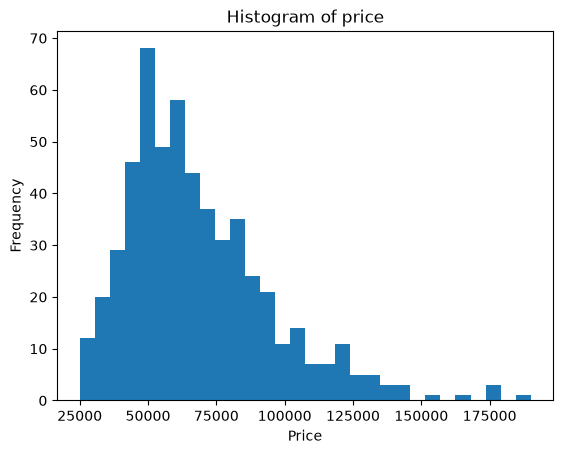

In [47]:
plt.figure()
plt.hist(data['price'], bins=30)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Histogram of price')
plt.show()

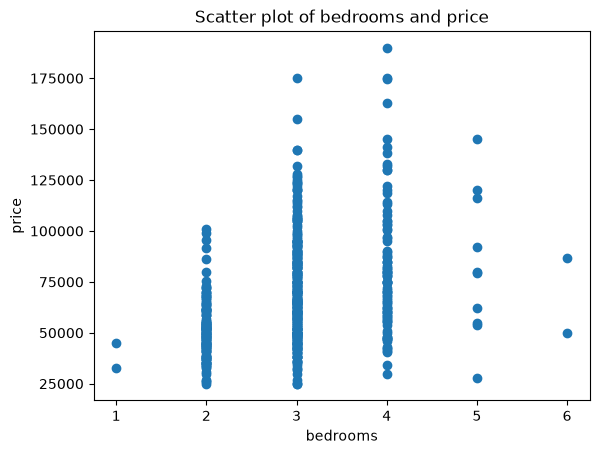

In [48]:
plt.figure()
plt.scatter(data['bedrooms'], data['price'])
plt.xlabel('bedrooms')
plt.ylabel('price')
plt.title('Scatter plot of bedrooms and price')
plt.show()

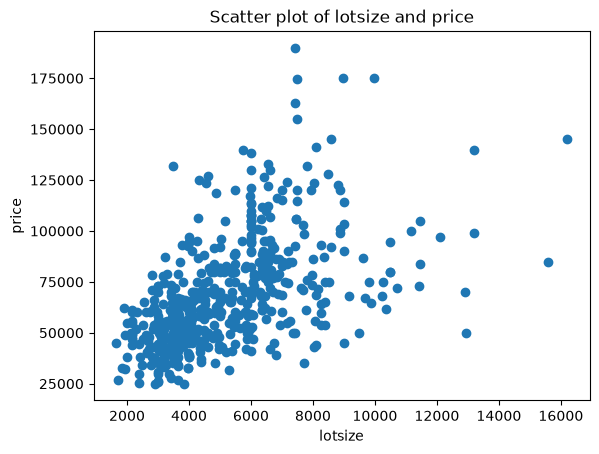

In [49]:
plt.figure()
plt.scatter(data['lotsize'], data['price'])
plt.xlabel('lotsize')
plt.ylabel('price')
plt.title('Scatter plot of lotsize and price')
plt.show()

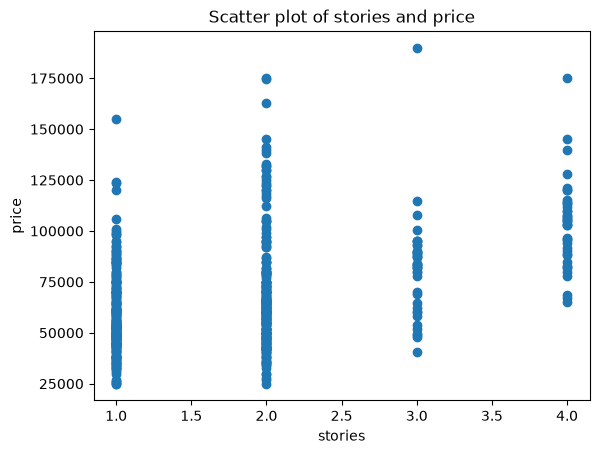

In [50]:
plt.figure()
plt.scatter(data['stories'], data['price'])
plt.xlabel('stories')
plt.ylabel('price')
plt.title('Scatter plot of stories and price')
plt.show()

In [51]:
target_columnn = 'price'
numeric_cols = ['lotsize', 'bedrooms', 'bathrms', 'stories', 'garagepl'] 
categorical_cols = ['driveway', 'recroom', 'fullbase', 'gashw', 'airco', 'prefarea']

In [52]:
all_used_cols = numeric_cols + categorical_cols + [target_columnn]
data = data[all_used_cols]

data.head()

,lotsize,bedrooms,bathrms,stories,garagepl,driveway,recroom,fullbase,gashw,airco,prefarea,price
0,5850.0,3,1,2,1.0,yes,no,yes,no,no,no,42000
1,4000.0,2,1,1,0.0,yes,no,no,no,no,no,38500
2,3060.0,3,1,1,0.0,yes,no,no,no,no,no,49500
3,6650.0,3,1,2,0.0,yes,yes,no,no,no,no,60500
4,6360.0,2,1,1,0.0,yes,no,no,no,no,no,61000


Factorize

In [57]:
data_factorized = data.copy()
factorize_maps = {}
for col in categorical_cols:
  codes, uniques = pd.factorize(data_factorized[col])
  data_factorized[col] = codes
  factorize_maps[col] = list(uniques)

data_factorized[categorical_cols].head()

,driveway,recroom,fullbase,gashw,airco,prefarea
0,0,0,0,0,0,0
1,0,0,1,0,0,0
2,0,0,1,0,0,0
3,0,1,1,0,0,0
4,0,0,1,0,0,0


factorize_maps

In [54]:
{'driveway': ['no', 'yes'], 
 'recroom': ['no', 'yes'], 
 'fullbase': ['no', 'yes'], 
 'gashw': ['no', 'yes'], 
 'airco': ['no', 'yes'], 
 'prefarea': ['no', 'yes']}

{'driveway': ['no', 'yes'],
 'recroom': ['no', 'yes'],
 'fullbase': ['no', 'yes'],
 'gashw': ['no', 'yes'],
 'airco': ['no', 'yes'],
 'prefarea': ['no', 'yes']}

# OHE - One Hot Encoder - One Hot кодирование

In [55]:
data_onehot = pd.get_dummies(data_factorized, columns=categorical_cols, drop_first=True)
data_onehot.head()


,lotsize,bedrooms,bathrms,stories,garagepl,price,driveway_0,driveway_1,recroom_0,recroom_1,fullbase_1,gashw_0,gashw_1,airco_0,airco_1,prefarea_0,prefarea_1
0,5850.0,3,1,2,1.0,42000,True,False,True,False,False,True,False,True,False,True,False
1,4000.0,2,1,1,0.0,38500,True,False,True,False,True,True,False,True,False,True,False
2,3060.0,3,1,1,0.0,49500,True,False,True,False,True,True,False,True,False,True,False
3,6650.0,3,1,2,0.0,60500,True,False,False,True,True,True,False,True,False,True,False
4,6360.0,2,1,1,0.0,61000,True,False,True,False,True,True,False,True,False,True,False
